# Revael — full wind-turbine pipeline and results

This notebook is a safe front end for the existing project scripts. It does not duplicate the modelling code: every stage calls the authoritative file in `scripts/`.

The official frozen test run is deliberately **not** included. Test results are read from the saved D-061 tables already committed to the repository. This prevents accidental test-set retuning.

Use **Run All** once the VS Code notebook kernel is set to the repository's `venv\Scripts\python.exe`. By default the notebook displays existing results without rebuilding the multi-gigabyte pipeline. Turn on the switches below when you want to rebuild stages.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    candidate = ROOT.parent
    if (candidate / "pyproject.toml").exists():
        ROOT = candidate
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Open this notebook from the ENGG2112-T3-G7 repository.")
os.chdir(ROOT)
print("Repository:", ROOT)
print("Python:", sys.executable)
print("Python version:", sys.version.split()[0])

Repository: C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7
Python: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe
Python version: 3.12.4


## Run controls

- Leave every switch `False` to inspect the existing saved results quickly.
- Set `RUN_DATA_PIPELINE = True` to rebuild alarms, SCADA Parquet, cleaning, labels and features from `data/raw/<year>/`.
- Set `RUN_VALIDATION_MODELS = True` after the data pipeline exists to rebuild NBM and validation model tables.
- Set `RUN_ANALYSES = True` for alert budgets, SHAP and robustness.
- Set `RUN_EXPLORATORY = True` only when you want the long validation-only exploratory runs.
- Set `RUN_REPORT_OUTPUTS = True` to regenerate figures and LaTeX tables.

In [2]:
RUN_DATA_PIPELINE = True
RUN_VALIDATION_MODELS = True
RUN_ANALYSES = True
RUN_EXPLORATORY = True
RUN_REPORT_OUTPUTS = True

# The official test years are never scored by this notebook.
ALLOW_FROZEN_TEST_RUN = False
assert not ALLOW_FROZEN_TEST_RUN, "Frozen test scoring is intentionally blocked (D-061)."

In [3]:
def run_script(script, *args):
    command = [sys.executable, str(ROOT / "scripts" / script), *map(str, args)]
    print("\n" + "=" * 88)
    print("RUN:", " ".join(command))
    started = time.perf_counter()
    completed = subprocess.run(command, cwd=ROOT, check=False)
    elapsed = time.perf_counter() - started
    if completed.returncode != 0:
        raise RuntimeError(f"{script} failed with exit code {completed.returncode}")
    print(f"DONE: {script} ({elapsed / 60:.1f} min)")


def require_file(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(f"Missing {relative_path}. Run the preceding stage first.")
    return path


def load_csv(relative_path):
    path = require_file(relative_path)
    frame = pd.read_csv(path)
    print(f"{relative_path}: {len(frame):,} rows × {len(frame.columns):,} columns")
    return frame

## 1. Check raw-data coverage

In [4]:
coverage = []
for year in range(2016, 2027):
    year_dir = ROOT / "data" / "raw" / str(year)
    files = list(year_dir.glob("*.csv")) if year_dir.exists() else []
    coverage.append({"year": year, "csv_files": len(files), "folder_exists": year_dir.exists()})
coverage = pd.DataFrame(coverage)
display(coverage)
if not coverage.folder_exists.all():
    print("Some raw year folders are missing. Follow docs/general/USAGE.md before rebuilding.")

,year,csv_files,folder_exists
0,2016,60,True
1,2017,60,True
2,2018,60,True
3,2019,60,True
4,2020,60,True
5,2021,60,True
6,2022,60,True
7,2023,60,True
8,2024,60,True
9,2025,60,True


## 2. Raw CSV → alarms, SCADA, cleaning, labels and features

This is the slow, disk-heavy section. `build_scada_parquet.py` skips Parquet outputs that already exist. Other builders replace their named outputs.

In [5]:
if RUN_DATA_PIPELINE:
    run_script("build_alarm_table.py")
    run_script("build_scada_parquet.py", "--workers", "4")
    run_script("build_clean_data.py")
    run_script("build_labels.py")
    run_script("build_features.py")
    run_script("check_feature_leakage.py")
else:
    print("Skipped data rebuild. Set RUN_DATA_PIPELINE = True to run it.")


RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\build_alarm_table.py
DONE: build_alarm_table.py (0.4 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\build_scada_parquet.py --workers 4
DONE: build_scada_parquet.py (0.1 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\build_clean_data.py
DONE: build_clean_data.py (5.0 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\build_labels.py
DONE: build_labels.py (0.1 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Sc

## 3. Normal behaviour and validation models

Models fit only on configured training years. These commands evaluate validation years and do not score the frozen test years.

In [6]:
if RUN_VALIDATION_MODELS:
    require_file("data/interim/features/daily_features.parquet")
    run_script("build_nbm.py")
    run_script("check_feature_leakage.py", "--nbm")
    run_script("make_baseline_table.py")
    run_script("tune_lgbm.py")
else:
    print("Skipped validation model rebuild. Set RUN_VALIDATION_MODELS = True to run it.")


RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\build_nbm.py
DONE: build_nbm.py (0.1 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\check_feature_leakage.py --nbm
DONE: check_feature_leakage.py (0.2 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\make_baseline_table.py
DONE: make_baseline_table.py (3.4 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\tune_lgbm.py
DONE: tune_lgbm.py (4.8 min)


## 4. Validation-only analysis and explanation

In [7]:
if RUN_ANALYSES:
    run_script("analyse_alert_budgets.py")
    run_script("run_shap.py")
    run_script("run_robustness.py")
else:
    print("Skipped analysis rebuild. Set RUN_ANALYSES = True to run it.")


RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\analyse_alert_budgets.py
DONE: analyse_alert_budgets.py (0.2 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\run_shap.py
DONE: run_shap.py (5.0 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\run_robustness.py
DONE: run_robustness.py (4.5 min)


## 5. Optional exploratory validation runs

These experiments can be lengthy. They remain validation-only and do not overwrite the frozen labels or score the test years.

In [8]:
if RUN_EXPLORATORY:
    run_script("run_exploratory.py")
    run_script("run_exploratory.py", "--round", "2")
    run_script("run_ranking.py")
    run_script("run_exploratory.py", "--round", "3")
    run_script("run_label_sensitivity.py")
else:
    print("Skipped exploratory runs. Set RUN_EXPLORATORY = True to run them.")


RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\run_exploratory.py
DONE: run_exploratory.py (5.7 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\run_exploratory.py --round 2
DONE: run_exploratory.py (4.9 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\run_ranking.py
DONE: run_ranking.py (0.1 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\run_exploratory.py --round 3
DONE: run_exploratory.py (18.5 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\p

## 6. Regenerate figures and report tables

In [9]:
if RUN_REPORT_OUTPUTS:
    run_script("make_report_figures.py")
    run_script("write_report_tables.py")
else:
    print("Using existing saved figures. Set RUN_REPORT_OUTPUTS = True to regenerate them.")


RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\make_report_figures.py
DONE: make_report_figures.py (0.5 min)

RUN: c:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\.venv\Scripts\python.exe C:\Users\revae\OneDrive\Documents\ChatGPT\ENGG2112\ENGG2112-T3-G7\scripts\write_report_tables.py
DONE: write_report_tables.py (0.0 min)


# Results dashboard

The remaining cells are read-only. They load the current CSV evidence and saved official test results.

In [10]:
labels = load_csv("reports/tables/label_summary.csv")
features = load_csv("reports/tables/feature_summary.csv")
validation = load_csv("reports/tables/t0_validation.csv")
test = load_csv("reports/tables/test_results.csv")

reports/tables/label_summary.csv: 6 rows × 15 columns
reports/tables/feature_summary.csv: 6 rows × 6 columns
reports/tables/t0_validation.csv: 48 rows × 25 columns
reports/tables/test_results.csv: 24 rows × 22 columns


## Label prevalence and available features

,target,split,labelled_rows,positives,positive_rate,episodes
0,A,train,22309,8315,37.3%,355
1,A,val,9690,4558,47.0%,217
2,A,test,17951,8099,45.1%,336
3,B,train,20911,10001,47.8%,434
4,B,val,8827,4346,49.2%,209
5,B,test,17281,8725,50.5%,382


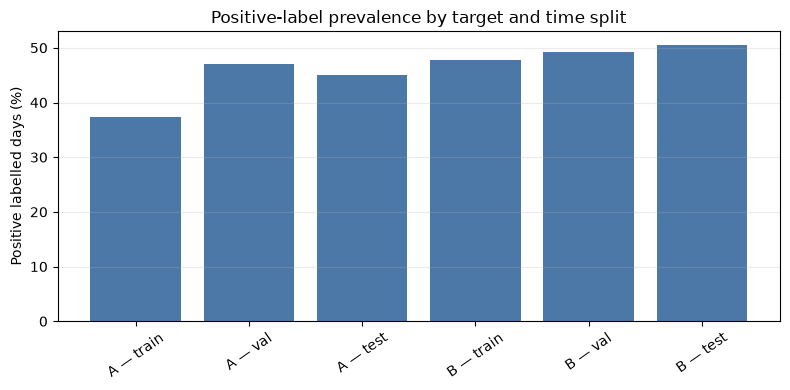

In [11]:
label_view = labels[
    ["target", "split", "labelled_rows", "positives", "positive_rate", "episodes"]
].copy()
label_view["positive_rate"] = (100 * label_view["positive_rate"]).round(1).astype(str) + "%"
display(label_view)

fig, ax = plt.subplots(figsize=(8, 4))
plot_labels = labels.copy()
plot_labels["series"] = plot_labels["target"] + " — " + plot_labels["split"]
ax.bar(plot_labels["series"], 100 * plot_labels["positive_rate"], color="#4C78A8")
ax.set_ylabel("Positive labelled days (%)")
ax.set_title("Positive-label prevalence by target and time split")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Validation PR-AUC against the random-score floor

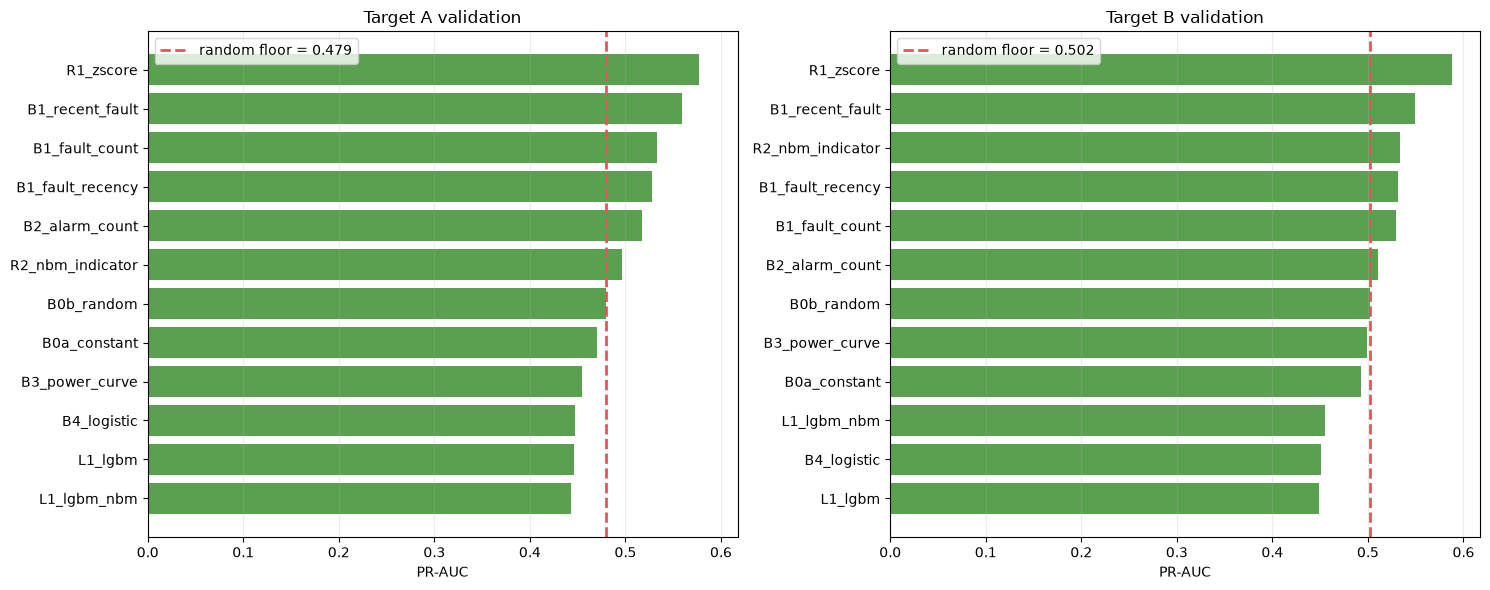

In [12]:
val = validation.loc[(validation["variant"] == "all") & (validation["split"] == "val")].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, target in zip(axes, ["A", "B"], strict=False):
    part = val.loc[val["target"].str.upper() == target].sort_values("pr_auc")
    ax.barh(part["model"], part["pr_auc"], color="#59A14F")
    floor = part["random_floor_pr_auc"].iloc[0]
    ax.axvline(
        floor, color="#E15759", linestyle="--", linewidth=2, label=f"random floor = {floor:.3f}"
    )
    ax.set_title(f"Target {target} validation")
    ax.set_xlabel("PR-AUC")
    ax.grid(axis="x", alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## Official frozen test result

These rows come from the one saved D-061 test run. The notebook does not refit or rescore them.

,target,model,pr_auc,pr_auc_lo,pr_auc_hi,random_floor_pr_auc,recall,false_alarms_per_turbine_month
0,A,B0a_constant,0.451,0.403,0.502,0.450,0.000,0.000
1,A,B0b_random,0.450,0.402,0.504,0.450,0.795,0.912
2,A,B1_recent_fault,0.441,0.377,0.502,0.450,0.131,0.784
3,A,B1_fault_count,0.451,0.396,0.506,0.450,0.065,0.471
4,A,B1_fault_recency,0.444,0.388,0.497,0.450,0.360,0.953
5,A,B2_alarm_count,0.453,0.407,0.501,0.450,0.271,0.622
6,A,R1_zscore,0.448,0.404,0.499,0.450,0.622,2.120
7,A,B3_power_curve,0.451,0.396,0.513,0.450,0.235,0.682
8,A,B4_logistic,0.462,0.416,0.514,0.450,0.202,0.427
9,A,R2_nbm_indicator,0.440,0.371,0.517,0.450,0.551,2.525


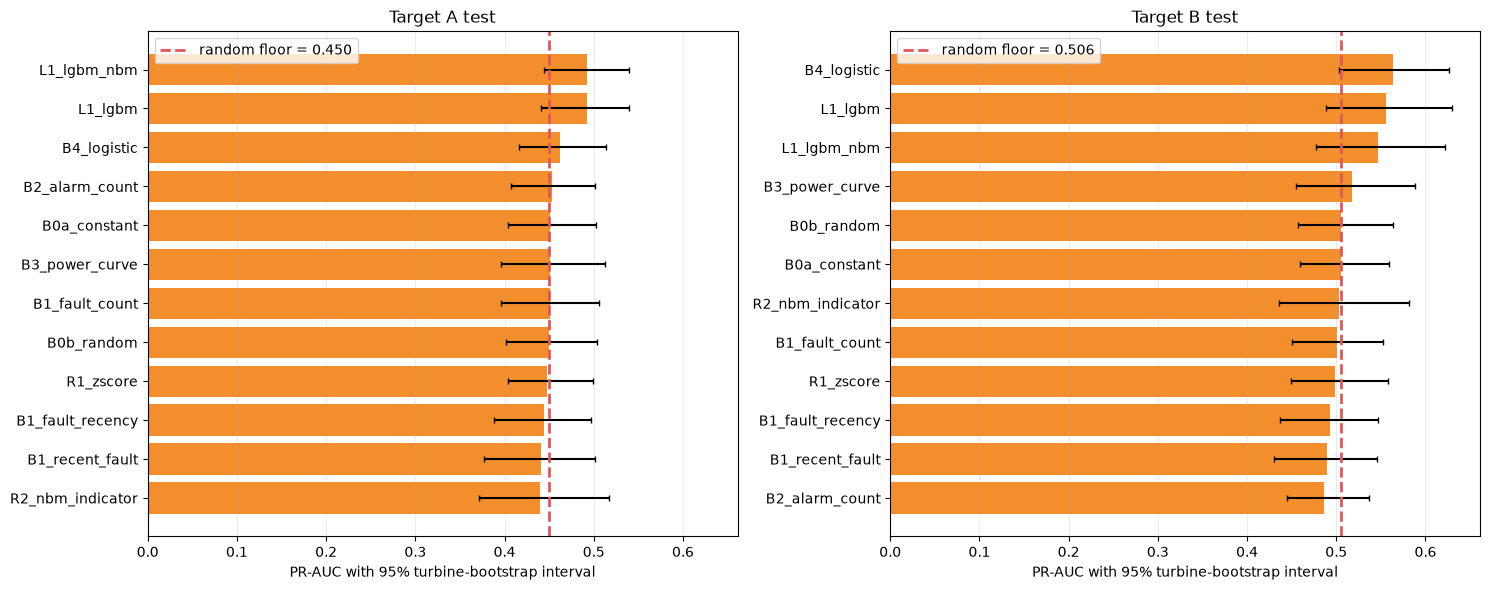

In [13]:
test_view = test[
    [
        "target",
        "model",
        "pr_auc",
        "pr_auc_lo",
        "pr_auc_hi",
        "random_floor_pr_auc",
        "recall",
        "false_alarms_per_turbine_month",
    ]
].copy()
display(test_view.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, target in zip(axes, ["A", "B"], strict=False):
    part = test.loc[test["target"].str.upper() == target].sort_values("pr_auc").copy()
    lower = (part["pr_auc"] - part["pr_auc_lo"]).clip(lower=0)
    upper = (part["pr_auc_hi"] - part["pr_auc"]).clip(lower=0)
    ax.barh(part["model"], part["pr_auc"], color="#F28E2B")
    ax.errorbar(
        part["pr_auc"], part["model"], xerr=[lower, upper], fmt="none", ecolor="black", capsize=2
    )
    floor = part["random_floor_pr_auc"].iloc[0]
    ax.axvline(
        floor, color="#E15759", linestyle="--", linewidth=2, label=f"random floor = {floor:.3f}"
    )
    ax.set_title(f"Target {target} test")
    ax.set_xlabel("PR-AUC with 95% turbine-bootstrap interval")
    ax.grid(axis="x", alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## Main project figures

### `reports/figures/02_labels/F08_label_geometry.png`

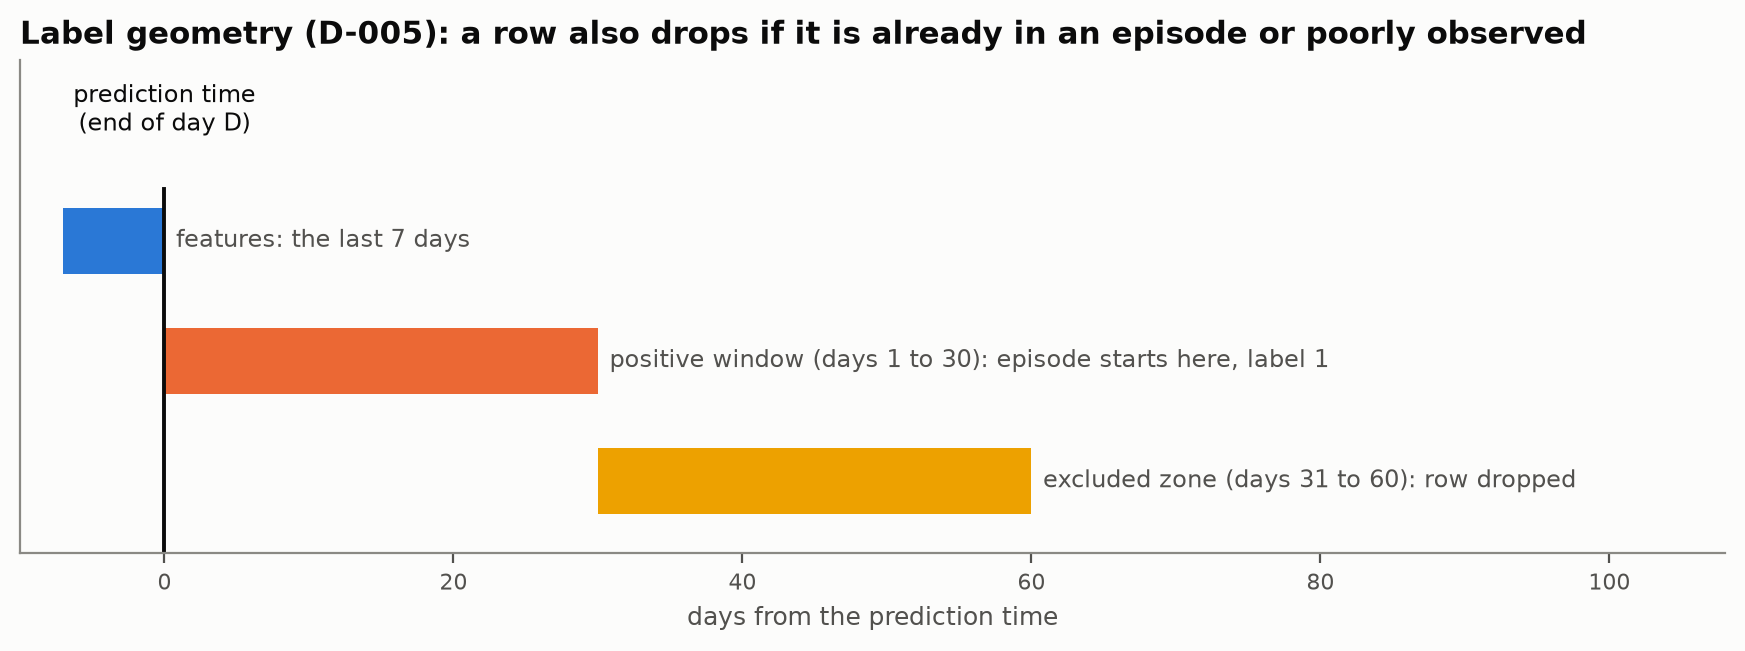

### `reports/figures/03_features/F11_feature_groups.png`

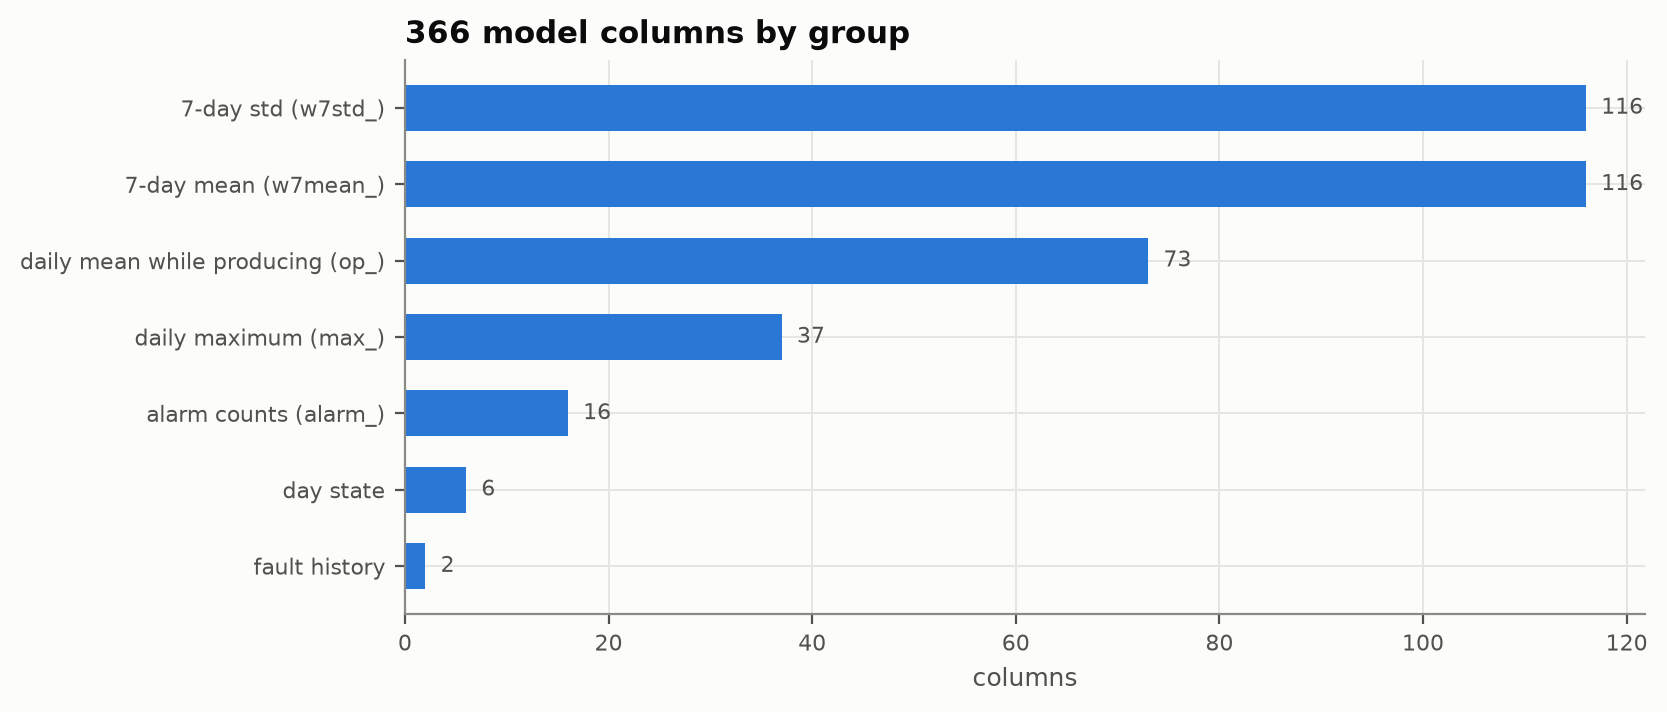

### `reports/figures/07_explain_robustness/F34_shap_top_features.png`

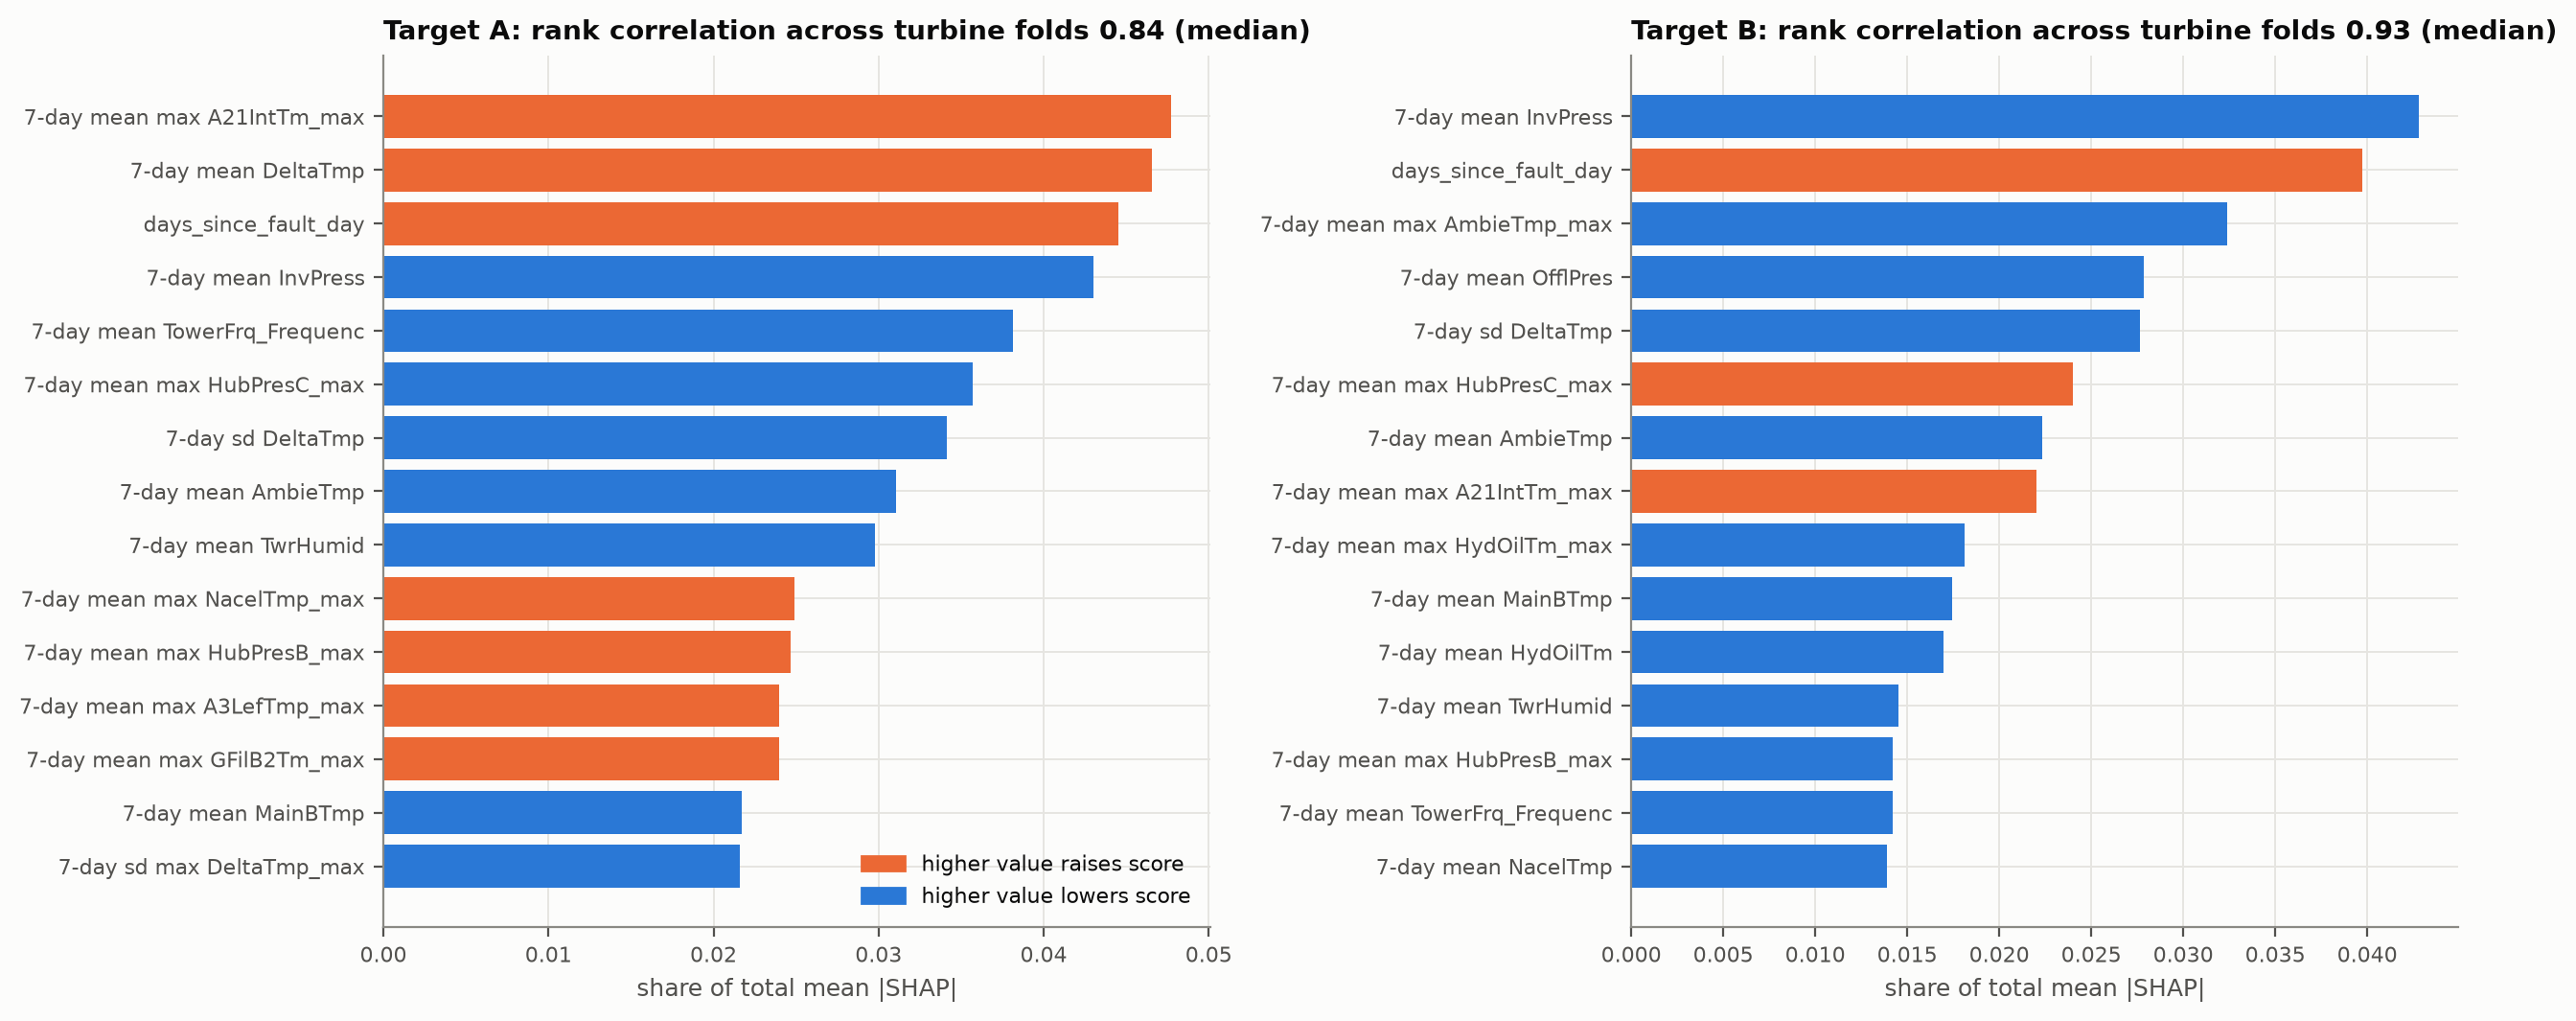

### `reports/figures/08_exploratory/F36_validation_to_test_shift.png`

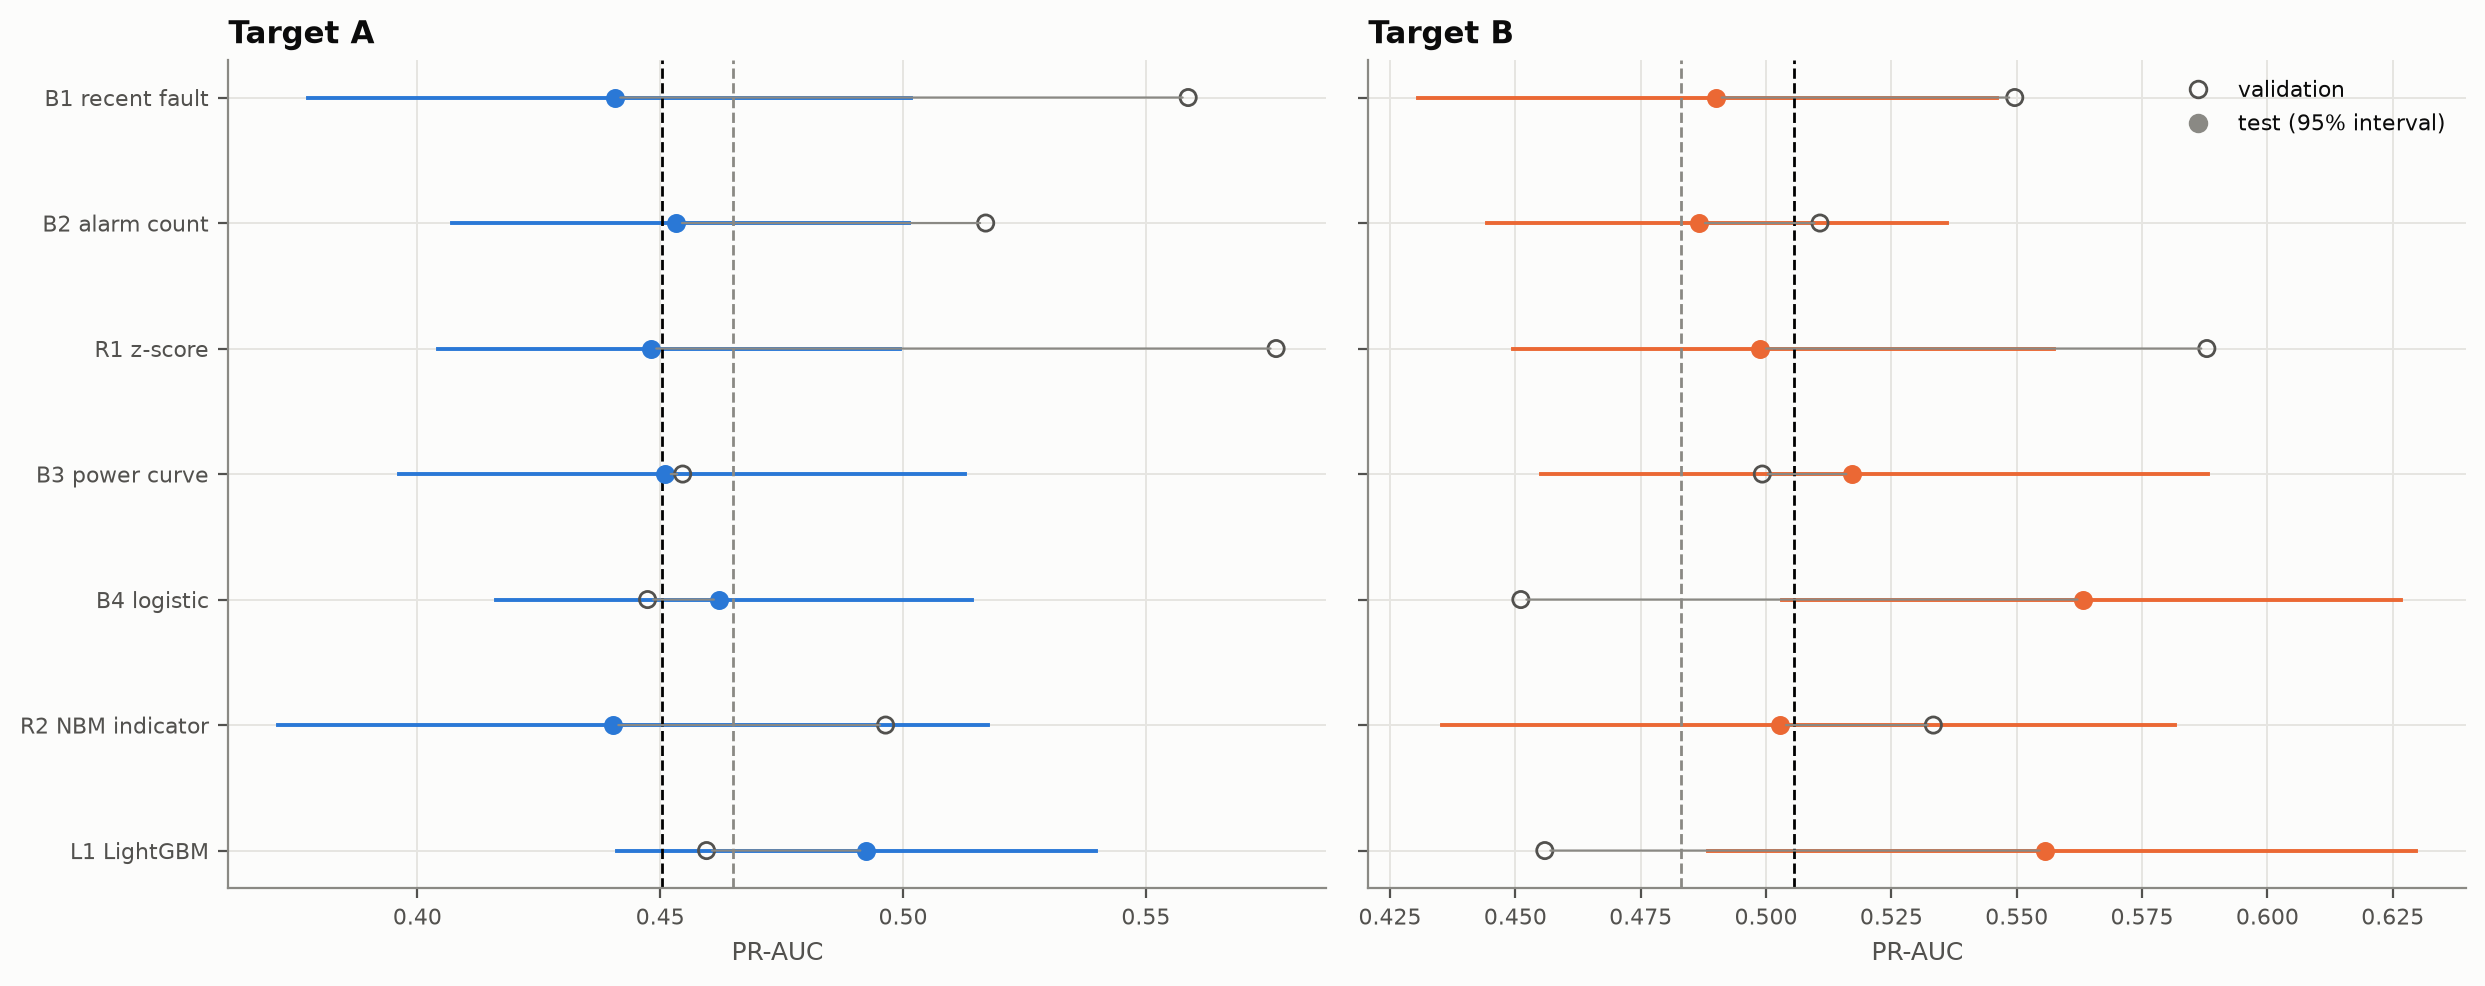

In [14]:
figure_paths = [
    "reports/figures/02_labels/F08_label_geometry.png",
    "reports/figures/03_features/F11_feature_groups.png",
    "reports/figures/07_explain_robustness/F34_shap_top_features.png",
    "reports/figures/08_exploratory/F36_validation_to_test_shift.png",
]
for relative_path in figure_paths:
    path = ROOT / relative_path
    if path.exists():
        display(Markdown(f"### `{relative_path}`"))
        display(Image(filename=str(path), width=1000))
    else:
        print("Missing figure:", relative_path)

## Conclusion

The saved test-year evidence does not show a model distinguishable from the random-score floor: every model's 95% turbine-bootstrap PR-AUC interval contains that floor. The validation leader did not retain its advantage on the test period, and validation-selected thresholds did not preserve a fixed false-alarm rate. The appropriate conclusion is a reproducible leakage-aware pipeline and an honest weak result, not a deployable maintenance-warning system.

Detailed interpretation: `reports/TEST_RESULTS.md`. Plain-language summary: `reports/STAKEHOLDER_SUMMARY.md`.